        # Lesson 8.10 · Keras & TensorFlow: A Rosetta Stone
        ### The same ideas you know from PyTorch, in the other big framework

        | | |
        |---|---|
        | ⏱️ **Time** | about 80 minutes |
        | 📚 **Before you start** | Lessons 8.3 – 8.6 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Map every PyTorch concept to its **Keras / TensorFlow** equivalent
- Build models with the **Sequential**, **Functional** and **subclassing** APIs and train them with `compile` / `fit`
- Use **callbacks** (early stopping, checkpoints, LR reduction) and avoid the **channels-last** pitfall
- Choose between PyTorch and TensorFlow/Keras for a given job

> 🌾 **The story so far.** Your future employer, the library you'll read on GitHub, or a model you must deploy to a phone may be TensorFlow. You already understand neural networks: this lesson is just *translation*.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import os
try:                                              # use TensorFlow if you have it ...
    import tensorflow as _tf
    os.environ.setdefault("KERAS_BACKEND", "tensorflow")
except Exception:                                 # ... otherwise Keras 3 happily runs on top of PyTorch
    os.environ["KERAS_BACKEND"] = "torch"
import keras
from keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
keras.utils.set_random_seed(0)
print("Keras", keras.__version__, "| running on backend:", keras.backend.backend())
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Keras 3.15.1 | running on backend: torch
Setup complete. Course folder: course


## 1 · The landscape

| Name | What it is |
|---|---|
| **PyTorch** | research-favourite framework; Pythonic, explicit training loops, dynamic graphs |
| **TensorFlow** | Google's framework; strong deployment story (TF Serving, TF Lite for phones, TF.js for browsers) |
| **Keras** | the high-level API: `Sequential`, `Dense`, `fit()`. Since **Keras 3** it is *multi-backend*: the same Keras code runs on TensorFlow, PyTorch or JAX |

> 💡 **Which should you use?** Both are excellent. Rule of thumb: **PyTorch** for research, custom architectures and learning (this course's primary framework); **Keras** for fast prototyping with the least code, and **TensorFlow** when the deployment target (mobile, browser, edge) demands it. Skills transfer almost completely.

This notebook runs on whichever backend you have installed: look at the printed line above.

## 2 · The Rosetta Stone

| Concept | PyTorch | Keras |
|---|---|---|
| Dense layer | `nn.Linear(n_in, n_out)` | `layers.Dense(n_out)` *(input size inferred)* |
| Activation | `nn.ReLU()` | `activation="relu"` or `layers.ReLU()` |
| Conv | `nn.Conv2d(C_in, C_out, 3)` | `layers.Conv2D(C_out, 3)` |
| Pooling | `nn.MaxPool2d(2)` | `layers.MaxPooling2D(2)` |
| Recurrent | `nn.LSTM(d, h, batch_first=True)` | `layers.LSTM(h)` |
| Dropout / BatchNorm | `nn.Dropout(p)`, `nn.BatchNorm2d(C)` | `layers.Dropout(p)`, `layers.BatchNormalization()` |
| Container | `nn.Sequential` / `nn.Module` | `keras.Sequential` / functional / `keras.Model` subclass |
| Image tensor layout | **(N, C, H, W)** channels-**first** | **(N, H, W, C)** channels-**last** (default) ⚠️ |
| Loss (multi-class) | `CrossEntropyLoss` (logits, class ids) | `SparseCategoricalCrossentropy(from_logits=True)` |
| Optimiser | `torch.optim.AdamW(params, lr)` | `keras.optimizers.AdamW(learning_rate)` |
| Training loop | write it (zero_grad → … → step) | **`model.compile(...)`; `model.fit(...)`** |
| Evaluation | loop under `no_grad()` | `model.evaluate(X, y)` |
| Prediction | `model(x)` | `model.predict(x)` |
| Early stopping | hand-written class | `callbacks.EarlyStopping(patience, restore_best_weights=True)` |
| Save / load | `state_dict` | `model.save("m.keras")`, `keras.models.load_model` |
| Data pipeline | `Dataset` / `DataLoader` | `tf.data.Dataset` or just NumPy arrays |
| Custom step | the loop itself | `tf.GradientTape` (TF backend) or override `train_step` |

In [2]:
d = load_digits()
X = (d.data / 16.0).astype("float32"); y = d.target
Xtmp, Xte, ytmp, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)
Xtr, Xva, ytr, yva = train_test_split(Xtmp, ytmp, test_size=0.25, stratify=ytmp, random_state=0)
print(Xtr.shape, Xva.shape, Xte.shape)

(1077, 64) (360, 64) (360, 64)


## 3 · Sequential API: the digits MLP in six lines
Compare with Lesson 8.5: same network, the training loop disappears into `fit`.

In [3]:
model = keras.Sequential([
    keras.Input(shape=(64,)),
    layers.Dense(128, activation="relu"), layers.Dropout(0.2),
    layers.Dense(64, activation="relu"),
    layers.Dense(10),                                           # logits, as in PyTorch
])
model.compile(optimizer=keras.optimizers.AdamW(2e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,226 (67.29 KB)

 Trainable params: 17,226 (67.29 KB)

 Non-trainable params: 0 (0.00 B)

test accuracy 0.975  (PyTorch ANN in Lesson 8.5: ~0.97)


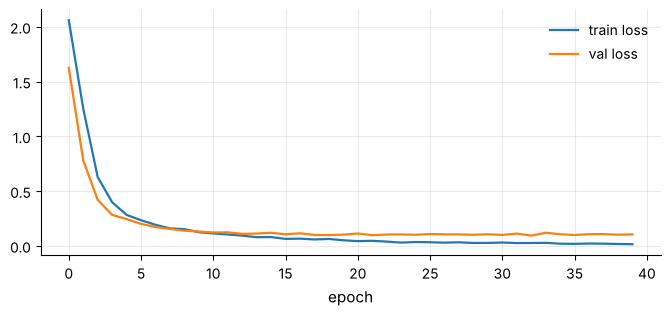

In [4]:
hist = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=40, batch_size=64, verbose=0)
loss, acc = model.evaluate(Xte, yte, verbose=0)
print(f"test accuracy {acc:.3f}  (PyTorch ANN in Lesson 8.5: ~0.97)")
plt.figure(figsize=(8, 3.2)); plt.plot(hist.history["loss"], label="train loss"); plt.plot(hist.history["val_loss"], label="val loss"); plt.legend(); plt.xlabel("epoch"); plt.show()

---
### 🧩 Exercise 1: Translate a PyTorch model to Keras  ⭐

This PyTorch network: `nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 10))` has **2,410** parameters.
Write the equivalent **Keras** model in `keras_model` (use `keras.Input(shape=(64,))` first) and store its parameter count in `n_params` (`model.count_params()`).

<details><summary>💡 Hint 1: gentle nudge</summary>

`keras.Sequential([keras.Input(shape=(64,)), layers.Dense(32, activation='relu'), layers.Dense(10)])`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Dense(32) on 64 inputs: 64·32 + 32 = 2,080 parameters; Dense(10): 32·10 + 10 = 330.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`n_params = keras_model.count_params()`

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [5]:
keras_model = keras.Sequential([keras.Input(shape=(64,)), layers.Dense(32, activation="relu"), layers.Dense(10)])
n_params = keras_model.count_params()
print(n_params)

2410


In [6]:
ag.check("2,410 parameters like the PyTorch model", n_params == 2410)
ag.check("output shape is (batch, 10)", keras_model is not None and tuple(keras_model(Xte[:3]).shape) == (3, 10))

✅  2,410 parameters like the PyTorch model
✅  output shape is (batch, 10)


True

## 4 · Callbacks: training-loop plug-ins
Instead of writing early stopping yourself (Lesson 8.4), pass **callbacks** to `fit`:

| Callback | Does |
|---|---|
| `EarlyStopping(monitor, patience, restore_best_weights=True)` | stops when validation stops improving; restores the best weights |
| `ModelCheckpoint("best.keras", save_best_only=True)` | saves the best model to disk |
| `ReduceLROnPlateau(factor, patience)` | cuts the learning rate when progress stalls |
| `LearningRateScheduler(fn)` | any schedule you like |
| `TensorBoard(log_dir)` | live training dashboards |

---
### 🧩 Exercise 2: Early stopping with a callback  ⭐⭐

Build a fresh Keras MLP (64 → 128 → 64 → 10 as above), compile it, and train with **up to 200 epochs** using
`callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)`. Store the `History` in `h2`,
the number of epochs actually run in `epochs_run`, and the test accuracy in `acc2`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`h2 = m2.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=200, batch_size=64, callbacks=[es], verbose=0)`

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`epochs_run = len(h2.history['loss'])`; `acc2 = m2.evaluate(Xte, yte, verbose=0)[1]`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [7]:
keras.utils.set_random_seed(1)
m2 = keras.Sequential([keras.Input(shape=(64,)), layers.Dense(128, activation="relu"), layers.Dense(64, activation="relu"), layers.Dense(10)])
m2.compile(optimizer=keras.optimizers.AdamW(2e-3), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
h2 = m2.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=200, batch_size=64, callbacks=[es], verbose=0)
epochs_run = len(h2.history["loss"])
acc2 = m2.evaluate(Xte, yte, verbose=0)[1]
print("epochs run:", epochs_run, "| test accuracy:", round(acc2, 3))

epochs run: 23 | test accuracy: 0.978


In [8]:
ag.check("training stopped well before 200 epochs", epochs_run is not None and epochs_run < 100)
ag.check("good test accuracy (> 94 %)", acc2 is not None and acc2 > 0.94)

✅  training stopped well before 200 epochs
✅  good test accuracy (> 94 %)


True

---
## 5 · The channels-last pitfall (convolutions)
PyTorch images are `(N, C, H, W)`; Keras defaults to `(N, H, W, C)`. Feeding the wrong layout doesn't crash: it silently **mixes up axes** and trains a worse model. Always print your shapes.

---
### 🧩 Exercise 3: A Keras CNN on digits  ⭐⭐

1. Reshape the data to Keras layout: `Xtr_i, Xva_i, Xte_i` with shape `(n, 8, 8, 1)` (channels **last**).
2. Build `cnn_k`: `Conv2D(16,3,padding="same",activation="relu")` → `MaxPooling2D(2)` → `Conv2D(32,3,padding="same",activation="relu")` → `MaxPooling2D(2)` → `Flatten` → `Dense(10)`.
3. Compile (AdamW 2e-3, sparse CE from logits), train 30 epochs with early stopping (patience 6, restore best), store the test accuracy in `cnn_k_acc` and the parameter count in `cnn_k_params`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`Xtr_i = Xtr.reshape(-1, 8, 8, 1)`: the channel axis goes **last**.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`keras.Sequential([keras.Input(shape=(8, 8, 1)), layers.Conv2D(16, 3, padding='same', activation='relu'), ...])`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Parameters: 160 + 4,640 + 1,290 = 6,090: the same network as the PyTorch CNN of Lesson 8.5.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [9]:
Xtr_i, Xva_i, Xte_i = [a.reshape(-1, 8, 8, 1) for a in (Xtr, Xva, Xte)]
keras.utils.set_random_seed(0)
cnn_k = keras.Sequential([
    keras.Input(shape=(8, 8, 1)),
    layers.Conv2D(16, 3, padding="same", activation="relu"), layers.MaxPooling2D(2),
    layers.Conv2D(32, 3, padding="same", activation="relu"), layers.MaxPooling2D(2),
    layers.Flatten(), layers.Dense(10),
])
cnn_k.compile(optimizer=keras.optimizers.AdamW(2e-3), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)
cnn_k.fit(Xtr_i, ytr, validation_data=(Xva_i, yva), epochs=30, batch_size=64, callbacks=[es], verbose=0)
cnn_k_acc = cnn_k.evaluate(Xte_i, yte, verbose=0)[1]
cnn_k_params = cnn_k.count_params()
print(cnn_k_params, "parameters | test accuracy", round(cnn_k_acc, 3))

6090 parameters | test accuracy 0.967


In [10]:
ag.check("images are channels-last (n, 8, 8, 1)", Xtr_i is not None and Xtr_i.shape[1:] == (8, 8, 1))
ag.check("6,090 parameters (same as the PyTorch CNN)", cnn_k_params == 6090)
ag.check("test accuracy above 94 %", cnn_k_acc is not None and cnn_k_acc > 0.94)

✅  images are channels-last (n, 8, 8, 1)
✅  6,090 parameters (same as the PyTorch CNN)
✅  test accuracy above 94 %


True

---
## 6 · Functional API and subclassing: when a straight line isn't enough
`Sequential` handles a straight stack. For **branches, skip connections, multiple inputs/outputs** use the **Functional API**: call layers on tensors like functions.

In [11]:
inp = keras.Input(shape=(16,))
h = layers.Dense(16, activation="relu")(inp)
res = layers.Add()([inp, h])                         # a skip (residual) connection
out = layers.Dense(1)(res)
resnet_toy = keras.Model(inp, out)
print("parameters:", resnet_toy.count_params())      # 16*16+16 + 16*1+1 = 289

parameters: 289


---
### 🧩 Exercise 4: A two-input model (functional API)  ⭐⭐⭐

A price model takes **two inputs**: a window of 8 numerical features (`num`, shape `(8,)`) and a **month** integer 0–11 (`month`, shape `(1,)`).
Build `two_in` so that: month → `Embedding(12, 3)` → `Flatten` (3 numbers); concatenated with `num` → `Dense(16, relu)` → `Dense(1)`.
Store `n_params` (should be **(12·3) + (11·16+16) + (16+1) = 36 + 192 + 17 = 245**) and the output shape for a batch of 5 in `out_shape`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`num = keras.Input(shape=(8,))`; `month = keras.Input(shape=(1,), dtype='int32')`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`m = layers.Flatten()(layers.Embedding(12, 3)(month))`; `z = layers.Concatenate()([num, m])` has 11 features.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`out = layers.Dense(1)(layers.Dense(16, activation='relu')(z))`; `two_in = keras.Model([num, month], out)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [12]:
num = keras.Input(shape=(8,))
month = keras.Input(shape=(1,), dtype="int32")
m = layers.Flatten()(layers.Embedding(12, 3)(month))
z = layers.Concatenate()([num, m])
out = layers.Dense(1)(layers.Dense(16, activation="relu")(z))
two_in = keras.Model([num, month], out)
n_params = two_in.count_params()
out_shape = tuple(two_in([np.zeros((5, 8), "float32"), np.zeros((5, 1), "int32")]).shape)
print(n_params, out_shape)

245 (5, 1)


In [13]:
ag.check("245 parameters", n_params == 245)
ag.check("output shape (5, 1)", out_shape == (5, 1))

✅  245 parameters
✅  output shape (5, 1)


True

**Subclassing** (`class MyModel(keras.Model)`) mirrors `nn.Module`: layers in `__init__`, computation in `call` (PyTorch's `forward`). Use it for dynamic logic. Quick tour:

In [14]:
class PriceNet(keras.Model):
    def __init__(self):
        super().__init__()
        self.d1, self.d2 = layers.Dense(32, activation="relu"), layers.Dense(1)
    def call(self, x):                                   # <- PyTorch's forward()
        return self.d2(self.d1(x))

pn = PriceNet(); _ = pn(np.zeros((2, 15), "float32"))           # weights are created on the first call
print("subclassed model parameters:", pn.count_params())

# LSTM in Keras: input shape is (batch, time, features): the SAME as PyTorch with batch_first=True
lstm_model = keras.Sequential([keras.Input(shape=(52, 4)), layers.LSTM(32), layers.Dense(8)])
print("LSTM model output shape:", tuple(lstm_model(np.zeros((6, 52, 4), "float32")).shape), "| params:", lstm_model.count_params())

subclassed model parameters: 545


LSTM model output shape: (6, 8) | params: 5000


### Custom training logic and saving
```python
# TensorFlow backend only: the manual loop with GradientTape (≈ PyTorch's zero_grad/backward/step):
with tf.GradientTape() as tape:
    loss = loss_fn(y, model(x, training=True))
grads = tape.gradient(loss, model.trainable_variables)
optimizer.apply(grads, model.trainable_variables)
```
Saving and restoring is one line each:

In [15]:
import tempfile, os
path = os.path.join(tempfile.gettempdir(), "digits_cnn.keras")
cnn_k.save(path)
restored = keras.models.load_model(path)
same = np.allclose(restored.predict(Xte_i, verbose=0), cnn_k.predict(Xte_i, verbose=0), atol=1e-5)
print("restored model predicts identically:", same)

restored model predicts identically: True


## 7 · Decision guide

| If you… | Reach for |
|---|---|
| are learning, doing research, writing custom layers/losses | **PyTorch** |
| want the shortest path from idea to working baseline | **Keras** |
| must ship to Android/iOS, a browser, or microcontrollers | **TensorFlow Lite / TF.js** (convert from Keras) |
| read a paper's code | whichever it uses: you can now read both |
| want to avoid lock-in | **Keras 3** (swap backends with one environment variable) |

## 🎓 Mini-quiz
1. `model.fit` replaces which five lines of the PyTorch loop?
2. Your Keras CNN gets 11 % accuracy on 10 classes after feeding NCHW images. Why?
3. Which Keras callback replaces our hand-written `EarlyStopping` class?

<details><summary>Answers</summary>

1. zero_grad → forward → loss → backward → step (plus the epoch/batch loops). 2. Keras expects channels-last; the axes were misread, so the conv filters saw nonsense. 3. `keras.callbacks.EarlyStopping(restore_best_weights=True)`.
</details>

        ---
        ## 🧾 Recap
        - Keras = high-level API (now multi-backend); TensorFlow = Google's engine with a strong deployment story.
- Concept mapping is almost 1-to-1; the big differences: **`compile`/`fit`**, **callbacks**, and **channels-last** image tensors.
- Sequential for stacks, **Functional** for branches/multi-input, **subclassing** for full control.
- You can now read and write both ecosystems.

**Next up:** Lesson 8.11; Project 4: an LSTM that forecasts agricultural prices, benchmarked against everything from Phase 7.